# 5b. Report false positives by organisational group

The saved Notebook 5 run did not include the organisational records needed for the role and department summaries. This addendum produces those reports from the existing scores.

**Inputs:** `scores_all_models.parquet` and the comparison table from Notebook 5; the policy and modelling module from Notebook 4; and `ldap_monthly.parquet` from Notebook 1. `context_curated.parquet` from Notebook 3 is optional and supports the access-tier table.

The notebook reconstructs the fixed-budget alerts and, when the comparison table is available, checks their true-positive and false-positive totals against the saved values. Matching counts are a consistency check, not by themselves a proof of identical row membership.

**Outputs:** role and department false-positive tables, the access-tier table when its input is available, and `fig_subgroup_fpr_role.png`.

No detector is fitted or rescored. The organisational attributes are attached for reporting. These are descriptive subgroup results, not separate hypothesis tests or a measured fairness benefit.

*Documentation copy, 8 November 2026. Notes edited for clarity; code, saved outputs and execution metadata are unchanged. This copy has not been rerun.*


In [1]:
# ============================================================
# 0. Setup — committed artefacts only; NOTHING is fitted here
# ============================================================
import os, glob, json, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
warnings.filterwarnings("ignore")
WORK = "/kaggle/working"

def find(pattern, required=True, what=""):
    hits = glob.glob(f"/kaggle/input/**/{pattern}", recursive=True)
    assert hits or not required, f"Required input not attached: {pattern} ({what})"
    return hits[0] if hits else None

P_SCORES = find("scores_all_models.parquet", what="NB5 committed output")
P_POLICY = find("threshold_policy.json",     what="NB4 output")
P_UTILS  = find("modelling_utils.py",        what="NB4 output")
P_LDAP   = find("ldap_monthly.parquet",      what="NB1 output")
P_CTXCUR = find("context_curated.parquet",   required=False, what="NB3 output (access-level table)")
P_CMP    = find("comparison_test_at_budget.csv", required=False, what="NB5 output (cross-check)")

import importlib.util
spec = importlib.util.spec_from_file_location("modelling_utils", P_UTILS)
mu = importlib.util.module_from_spec(spec); spec.loader.exec_module(mu)
UTILS_SHA = hashlib.sha256(open(P_UTILS, "rb").read()).hexdigest()[:16]
POLICY = json.load(open(P_POLICY))
DET, K = POLICY["detector"], float(POLICY["k_pct"])
print(f"utils sha256[:16]={UTILS_SHA} | FROZEN policy: detector={DET}, k={K}%")

scores = pd.read_parquet(P_SCORES)
scores["user"] = scores["user"].astype(str)
scores["day"] = pd.to_datetime(scores["day"])
CONFIGS = ["M0", "M1", "M2", "M3"]
assert all(f"{c}_{DET}" in scores.columns for c in CONFIGS)
test = scores[scores.partition == "test"].reset_index(drop=True)
print(f"test partition from committed NB5 scores: {len(test):,} user-days, "
      f"{int(test.label.sum())} malicious")

# --- reconstruct the frozen-budget alert sets (deterministic rank; no model runs) ---
ALERT = {c: mu.alerts_at_budget(test[f"{c}_{DET}"].to_numpy(), K) for c in CONFIGS}
print("\nself-check vs committed comparison table:")
chk = pd.read_csv(P_CMP) if P_CMP else None
for c in CONFIGS:
    tp, fp, fn, tn = mu.counts(test.label.to_numpy(), ALERT[c])
    line = f"  {c}: alerts={int(ALERT[c].sum()):,}  TP={tp}  FP={fp:,}"
    if chk is not None:
        row = chk[chk.config == c].iloc[0]
        ok = (tp == int(row.tp)) and (fp == int(row.fp))
        assert ok, (f"{c}: reconstructed alerts do not match committed NB5 "
                    f"({tp}/{fp} vs {int(row.tp)}/{int(row.fp)})")
        line += "  == committed OK"
    print(line)
if chk is None:
    print("  (comparison_test_at_budget.csv not attached — counts printed uncrosschecked)")

utils sha256[:16]=147d19b0977c79e8 | FROZEN policy: detector=if, k=1.0%
test partition from committed NB5 scores: 395,549 user-days, 38 malicious

self-check vs committed comparison table:
  M0: alerts=3,955  TP=5  FP=3,950  == committed OK
  M1: alerts=3,955  TP=4  FP=3,951  == committed OK
  M2: alerts=3,955  TP=5  FP=3,950  == committed OK
  M3: alerts=3,955  TP=5  FP=3,950  == committed OK


## 1. Build the subgroup tables

Join the test observations to the organisational timeline, using the available snapshot history and the forward/backward fill rules in the cell. This reporting join is separate from the original model matrices; complete coverage does not independently establish historical validity.

For benign user-days, report each configuration's false-positive count and rate by role and department, plus access tier when available. The M2-minus-M0 difference shows the direction of the descriptive change within each group.

The figure displays the twelve roles with the highest baseline rate among those with at least 2,000 benign days. This display rule is specific to this notebook and should not be confused with later dissertation table selections.


NOTE: 101 test user-months fall outside their user's LDAP snapshot coverage (101 users) — attributes carried forward from the last known snapshot. Sample:
   user   month
AAT2913 2011-02
ACS0128 2011-01
AEG1121 2011-03
AEH0187 2011-03
AGF1810 2011-03
AGF2302 2011-03
AJV0176 2011-03
ALB1254 2011-03

subgroup FPR by ROLE (top 15 by benign exposure):
                       days  fp_M0  fp_M1  fp_M2  fp_M3    fpr_M0    fpr_M1    fpr_M2    fpr_M3  d_fpr_M2_M0
role                                                                                                        
ProductionLineWorker  40503    274    283    270    204  0.006765  0.006987  0.006666  0.005037    -0.000099
Technician            40271     61    150    116     31  0.001515  0.003725  0.002880  0.000770     0.001366
ElectricalEngineer    39853    184    143    255    153  0.004617  0.003588  0.006399  0.003839     0.001782
Salesman              35791    275    260    281    215  0.007683  0.007264  0.007851  0.006007     0.000

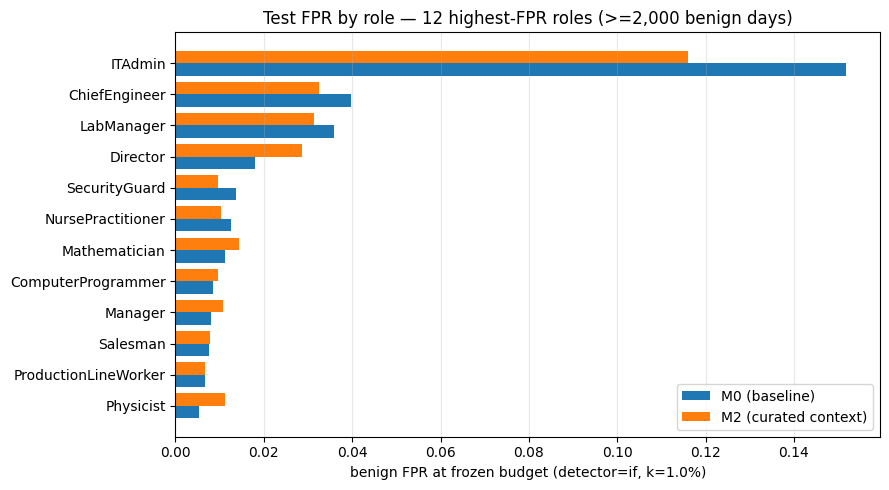

In [2]:
# ============================================================
# 1. Subgroup FPR tables — attributes joined for REPORTING ONLY
# ============================================================
ldap = pd.read_parquet(P_LDAP)
ldap["user_id"] = ldap["user_id"].astype(str)
snap = (ldap[["user_id", "snapshot", "role", "department"]]
        .rename(columns={"user_id": "user", "snapshot": "month"}))
snap["month"] = snap["month"].astype(str)

rows = test[["user", "day", "label"]].copy()
for c in CONFIGS:
    rows[f"alert_{c}"] = ALERT[c]
rows["month"] = rows["day"].dt.to_period("M").astype(str)
# Build the attribute timeline over each user's FULL history (their actual LDAP
# snapshot months UNION the test months we need), then ffill/bfill and slice back.
# Rationale: a user active in the test window AFTER their last LDAP appearance
# (departed/dropped from later snapshots) has no earlier month to ffill from if the
# frame holds test months only — NB3 never hit this because its frame spanned the
# whole study period. Attributes for such users are carried forward from their last
# known snapshot (documented choice; affected user-months are printed below).
need = rows[["user", "month"]].drop_duplicates()
tl = (pd.concat([snap, need.assign(role=np.nan, department=np.nan)], ignore_index=True)
        .sort_values(["user", "month"])
        .drop_duplicates(["user", "month"], keep="first"))   # snapshot rows win
tl[["role", "department"]] = tl.groupby("user")[["role", "department"]].ffill()
tl[["role", "department"]] = tl.groupby("user")[["role", "department"]].bfill()
um = need.merge(tl, on=["user", "month"], how="left")
carried = need.merge(snap[["user", "month"]].assign(_hit=1),
                     on=["user", "month"], how="left")
carried = carried[carried["_hit"].isna()]
if len(carried):
    print(f"NOTE: {len(carried)} test user-months fall outside their user's LDAP "
          f"snapshot coverage ({carried['user'].nunique()} users) — attributes "
          f"carried forward from the last known snapshot. Sample:")
    print(carried[["user", "month"]].head(8).to_string(index=False))
unmatched = int(um["role"].isna().sum())
assert unmatched == 0, (f"{unmatched} user-months STILL without LDAP attributes "
                        f"after full-timeline fill — users absent from LDAP entirely: "
                        f"{sorted(um.loc[um.role.isna(), 'user'].unique())[:5]}")
rows = rows.merge(um, on=["user", "month"], how="left")
if P_CTXCUR:
    acc = pd.read_parquet(P_CTXCUR)[["user", "day", "access_level"]]
    acc["user"] = acc["user"].astype(str); acc["day"] = pd.to_datetime(acc["day"])
    rows = rows.merge(acc, on=["user", "day"], how="left")

def subgroup_table(df, by):
    ben = df[df.label == 0]
    agg = {"days": ("alert_M0", "size")}
    for c in CONFIGS:
        agg[f"fp_{c}"] = (f"alert_{c}", "sum")
    g = ben.groupby(by).agg(**agg)
    for c in CONFIGS:
        g[f"fpr_{c}"] = g[f"fp_{c}"] / g["days"]
    g["d_fpr_M2_M0"] = g["fpr_M2"] - g["fpr_M0"]
    return g.sort_values("days", ascending=False)

TABLES = {}
for by in (["role", "department"] + (["access_level"] if P_CTXCUR else [])):
    t = subgroup_table(rows, by)
    t.to_csv(f"{WORK}/subgroup_fpr_{by}.csv")
    TABLES[by] = t
    print(f"\nsubgroup FPR by {by.upper()} (top 15 by benign exposure):")
    print(t.head(15).to_string())

# figure: roles ranked by baseline FPR — where does M2 move the needle?
tr = TABLES["role"]
top = tr[tr.days >= 2000].sort_values("fpr_M0", ascending=False).head(12)
fig, ax = plt.subplots(figsize=(9, 5))
ypos = np.arange(len(top))
ax.barh(ypos + 0.2, top["fpr_M0"], height=0.4, label="M0 (baseline)")
ax.barh(ypos - 0.2, top["fpr_M2"], height=0.4, label="M2 (curated context)")
ax.set_yticks(ypos); ax.set_yticklabels(top.index); ax.invert_yaxis()
ax.set_xlabel(f"benign FPR at frozen budget (detector={DET}, k={K}%)")
ax.set_title("Test FPR by role — 12 highest-FPR roles (>=2,000 benign days)")
ax.legend(); ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.savefig(f"{WORK}/fig_subgroup_fpr_role.png", dpi=150)
plt.show()

## 2. Review the reporting audit

The audit records the policy and module identifier, reports whether the count comparison was available, and lists the generated files.

No model inputs, scores or primary verdict are changed. The statement that attributes are for reporting refers to this addendum; organisational attributes were used to construct features elsewhere in the research pipeline.


In [3]:
# ============================================================
# 2. Audit — reporting addendum, not an analysis change
# ============================================================
print("SUBGROUP ADDENDUM AUDIT")
print("-" * 62)
print(f"1. NO model was fitted or scored: all scores read from NB5's committed")
print(f"   scores_all_models.parquet; alert sets reconstructed at the frozen")
print(f"   policy (detector={DET}, k={K}%) via NB4's modelling_utils")
print(f"   (sha256[:16]={UTILS_SHA}) — deterministic rank, no randomness.")
if P_CMP:
    print(f"2. Reconstruction cross-checked against the committed comparison table:")
    print(f"   TP/FP counts match for all four configurations (asserted above).")
print(f"3. LDAP role/department joined for REPORTING ONLY — attributes are not")
print(f"   features anywhere; the canonical verdict and all NB5 tables are")
print(f"   unchanged by this notebook's existence.")
print(f"4. Test partition used descriptively (subgroup FP tallies of alert sets")
print(f"   already produced by the pre-registered run) — no new inference.")
print("-" * 62)
print("\nfiles in /kaggle/working:")
for f in sorted(os.listdir(WORK)):
    p = f"{WORK}/{f}"
    if os.path.isfile(p):
        print(f"  {f:34s} {os.path.getsize(p)/1e6:6,.1f} MB")

SUBGROUP ADDENDUM AUDIT
--------------------------------------------------------------
1. NO model was fitted or scored: all scores read from NB5's committed
   scores_all_models.parquet; alert sets reconstructed at the frozen
   policy (detector=if, k=1.0%) via NB4's modelling_utils
   (sha256[:16]=147d19b0977c79e8) — deterministic rank, no randomness.
2. Reconstruction cross-checked against the committed comparison table:
   TP/FP counts match for all four configurations (asserted above).
3. LDAP role/department joined for REPORTING ONLY — attributes are not
   features anywhere; the canonical verdict and all NB5 tables are
   unchanged by this notebook's existence.
4. Test partition used descriptively (subgroup FP tallies of alert sets
   already produced by the pre-registered run) — no new inference.
--------------------------------------------------------------

files in /kaggle/working:
  __notebook__.ipynb                    0.1 MB
  fig_subgroup_fpr_role.png             0.1 MB
